# 01 · Electricity prices: hvakosterstrommen.no

Exploration only. Goal: understand format, resolution, history length and publish time before writing the Bronze spec.

API: `https://www.hvakosterstrommen.no/api/v1/prices/{YYYY}/{MM-DD}_{AREA}.json`, one file per day and price area (NO1–NO5), no key.

In [1]:
import json
import urllib.error
import urllib.request
from datetime import date, timedelta

import pandas as pd

UA = {"User-Agent": "energy-data-platform/0.1 (exploration)"}
AREAS = ["NO1", "NO2", "NO3", "NO4", "NO5"]


def fetch(day: date, area: str):
    """One day's prices as a list of dicts, or None if the file doesn't exist (404)."""
    url = f"https://www.hvakosterstrommen.no/api/v1/prices/{day:%Y/%m-%d}_{area}.json"
    try:
        with urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=15) as r:
            return json.load(r)
    except urllib.error.HTTPError as e:
        if e.code == 404:
            return None
        raise


today = date.today()

## 1. Raw format

In [2]:
raw = fetch(today, "NO2")
raw[:2]

[{'NOK_per_kWh': 1.72364,
  'EUR_per_kWh': 0.16224,
  'EXR': 10.624,
  'time_start': '2026-10-20T00:00:00+02:00',
  'time_end': '2026-10-20T01:00:00+02:00'},
 {'NOK_per_kWh': 1.70887,
  'EUR_per_kWh': 0.16085,
  'EXR': 10.624,
  'time_start': '2026-10-20T01:00:00+02:00',
  'time_end': '2026-10-20T02:00:00+02:00'}]

In [3]:
df = pd.DataFrame(raw)
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   NOK_per_kWh  24 non-null     float64
 1   EUR_per_kWh  24 non-null     float64
 2   EXR          24 non-null     float64
 3   time_start   24 non-null     str    
 4   time_end     24 non-null     str    
dtypes: float64(3), str(2)
memory usage: 1.1 KB


,NOK_per_kWh,EUR_per_kWh,EXR,time_start,time_end
0,1.72364,0.16224,10.624,2026-10-20T00:00:00+02:00,2026-10-20T01:00:00+02:00
1,1.70887,0.16085,10.624,2026-10-20T01:00:00+02:00,2026-10-20T02:00:00+02:00
2,1.72332,0.16221,10.624,2026-10-20T02:00:00+02:00,2026-10-20T03:00:00+02:00
3,1.70388,0.16038,10.624,2026-10-20T03:00:00+02:00,2026-10-20T04:00:00+02:00
4,1.73745,0.16354,10.624,2026-10-20T04:00:00+02:00,2026-10-20T05:00:00+02:00


Things to note: `time_start`/`time_end` are **local time with offset** (`+01:00`/`+02:00`), prices are **per kWh**, `EXR` is the EUR→NOK rate used.

## 2. Resolution and rows per day

Normal days should have 24 rows; DST days 23 (spring) or 25 (autumn). The Nordic market moved to 15-minute resolution on 2025-10-01, so check whether this API returns 24 or 96 rows after that date.

In [4]:
check_days = {
    "today": today,
    "DST spring 2026-03-29": date(2026, 3, 29),
    "DST autumn 2025-10-26": date(2025, 10, 26),
    "before 15-min (2025-09-30)": date(2025, 9, 30),
    "after 15-min (2025-10-01)": date(2025, 10, 1),
}
for label, d in check_days.items():
    rows = fetch(d, "NO2")
    if rows is None:
        print(f"{label:28} missing")
        continue
    step = pd.Timestamp(rows[1]["time_start"]) - pd.Timestamp(rows[0]["time_start"])
    print(f"{label:28} rows={len(rows):3}  step={step}")

today                        rows= 24  step=0 days 01:00:00
DST spring 2026-03-29        rows= 23  step=0 days 01:00:00
DST autumn 2025-10-26        rows= 25  step=0 days 01:00:00
before 15-min (2025-09-30)   rows= 24  step=0 days 01:00:00
after 15-min (2025-10-01)    rows= 24  step=0 days 01:00:00


## 3. How far back does history go?

Binary search per area for the first day that returns data (assumes no gaps after it; section 5 checks the last 30 days).

In [5]:
def first_day(area):
    lo, hi = date(2020, 1, 1), today  # lo: assumed missing, hi: known present
    assert fetch(lo, area) is None
    while (hi - lo).days > 1:
        mid = lo + timedelta(days=(hi - lo).days // 2)
        if fetch(mid, area):
            hi = mid
        else:
            lo = mid
    return hi


{area: first_day(area) for area in AREAS}

{'NO1': datetime.date(2021, 9, 7),
 'NO2': datetime.date(2021, 10, 1),
 'NO3': datetime.date(2021, 10, 1),
 'NO4': datetime.date(2021, 11, 1),
 'NO5': datetime.date(2021, 10, 1)}

## 4. When are tomorrow's prices published?

The day-ahead auction result is usually out around 13:00 Oslo time. Re-run this cell before and after to see.

In [6]:
tomorrow = today + timedelta(days=1)
print("Now (Oslo):", pd.Timestamp.now(tz="Europe/Oslo").strftime("%Y-%m-%d %H:%M"))
print("Tomorrow available:", fetch(tomorrow, "NO2") is not None)

Now (Oslo): 2026-10-20 11:28
Tomorrow available: False


## 5. All areas, last 30 days: completeness, duplicates, value ranges

In [7]:
frames = []
for area in AREAS:
    for i in range(30):
        d = today - timedelta(days=i)
        rows = fetch(d, area)
        if rows:
            frames.append(pd.DataFrame(rows).assign(area=area, day=d))
month = pd.concat(frames, ignore_index=True)
month["time_start"] = pd.to_datetime(month["time_start"], utc=True)

month.groupby("area").agg(
    days=("day", "nunique"),
    rows=("NOK_per_kWh", "size"),
    min_nok=("NOK_per_kWh", "min"),
    mean_nok=("NOK_per_kWh", "mean"),
    max_nok=("NOK_per_kWh", "max"),
).round(3)

,days,rows,min_nok,mean_nok,max_nok
area,,,,,
NO1,30,720,0.098,1.438,2.519
NO2,30,720,-0.001,1.516,2.676
NO3,30,720,0.057,1.037,2.279
NO4,30,720,-0.019,0.300,1.532
NO5,30,720,0.098,1.389,2.455


In [8]:
print("Duplicate (area, time_start):", month.duplicated(["area", "time_start"]).sum())
print("Negative prices:", (month["NOK_per_kWh"] < 0).sum())
print("Nulls per column:")
print(month.isna().sum())

Duplicate (area, time_start): 0
Negative prices: 8
Nulls per column:
NOK_per_kWh    0
EUR_per_kWh    0
EXR            0
time_start     0
time_end       0
area           0
day            0
dtype: int64


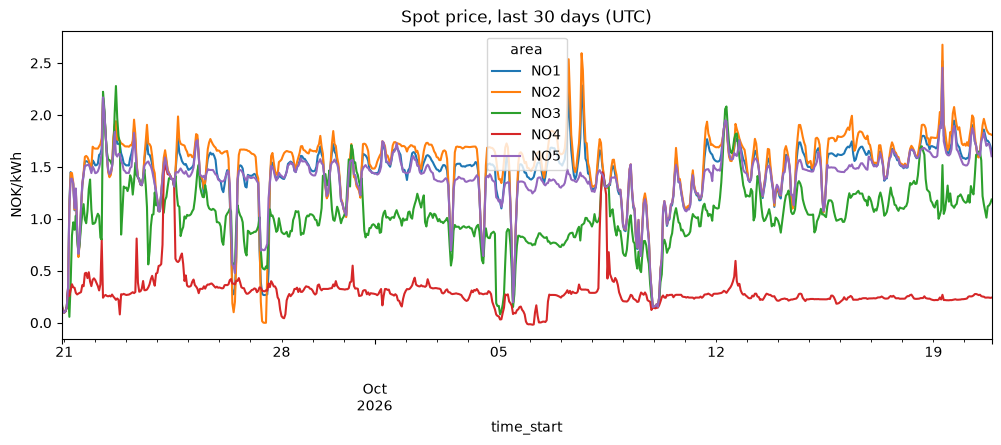

In [ ]:
month.pivot_table(index="time_start", columns="area", values="NOK_per_kWh").plot(
    figsize=(12, 4), ylabel="NOK/kWh", title="Spot price, last 30 days (UTC)"
);

'''
NO1: østlandet
NO2: Sørlandet og Rogaland
NO3: Midtnorge
NO4: nord-norge
NO5 - Vestlandet
'''

## Findings

Fill in, then copy the important ones to `docs/data-sources.md`:

- Resolution / rows per day: 24
- History starts: 2021
- Tomorrow published at: 13:00?
- Gaps, duplicates, nulls: none/few
- Price range, negative prices: 8 negative prices (totally normal during summer)